# Homework 8.2 - Part IV

## Hidden-State Reconstruction

The observer sees only

$$
Y_t=X_t-L_t.
$$

We study two information regimes.

### Regime A

The observer knows:

- all model parameters;
- the observation times;
- the complete exact grid path $Y_n$;
- the exact initial distortion $L_0$.

### Regime B

The observer knows:

- all model parameters;
- the observation times;
- the complete exact grid path $Y_n$;
- only that

$$
L_0\in[-1,1].
$$

The observer does not know $X_0$ in Regime B.

The true hidden states are used only after estimation to score reconstruction quality.

## Reconstruction equation

Since

$$
X=Y+L,
$$

the distortion equation becomes

$$
\frac{dL}{dt}
=
-\kappa
\frac{|Y(t)+L|}
{1+\eta|L|}.
$$

With a known initial $L_0$ and exact continuous observation path $Y(t)$, this is an ordinary initial-value problem for $L$.

Under the regularity of this right-hand side in $L$, the hidden history is uniquely determined.

For Euler-Maruyama synthetic data we use the matching grid recursion

$$
\widehat L_{n+1}
=
\widehat L_n
-
\kappa
\frac{|Y_n+\widehat L_n|}
{1+\eta|\widehat L_n|}
\Delta t.
$$

Then

$$
\widehat X_n=Y_n+\widehat L_n.
$$

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_2"

config = json.loads(
    (
        DATA_DIR
        / "hw8_2_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(
    config["a"]
)

KAPPA = float(
    config["kappa"]
)

SIGMA = float(
    config["sigma"]
)

ETA = float(
    config["eta"]
)

TRUE_X0 = float(
    config["x0"]
)

TRUE_L0 = float(
    config["l0"]
)

DT = 0.01
T = 20.0
SEED = 63841

N_STEPS = int(
    round(
        T / DT
    )
)

rng = np.random.default_rng(
    SEED
)

x = np.empty(
    N_STEPS + 1,
    dtype=float,
)

l = np.empty(
    N_STEPS + 1,
    dtype=float,
)

x[0] = TRUE_X0
l[0] = TRUE_L0

for n in range(
    N_STEPS
):
    z = rng.normal()

    x[
        n + 1
    ] = (
        x[n]
        + A
        * (
            -x[n]
            + l[n]
        )
        * DT
        + SIGMA
        * np.sqrt(
            DT
        )
        * z
    )

    l[
        n + 1
    ] = (
        l[n]
        - KAPPA
        * np.abs(
            x[n]
        )
        / (
            1.0
            + ETA
            * np.abs(
                l[n]
            )
        )
        * DT
    )


y = (
    x
    - l
)

time = (
    np.arange(
        N_STEPS + 1
    )
    * DT
)

synthetic = pd.DataFrame({
    "t": time,
    "Y_observed": y,
    "X_hidden_truth": x,
    "L_hidden_truth": l,
})

synthetic.to_csv(
    DATA_DIR
    / "part4_synthetic_observation.csv",
    index=False,
)

print(
    synthetic.head().to_string(
        index=False
    )
)

   t  Y_observed  X_hidden_truth  L_hidden_truth
0.00    1.000000        1.000000        0.000000
0.01    0.995037        0.994537       -0.000500
0.02    0.996709        0.995712       -0.000997
0.03    1.012299        1.010805       -0.001494
0.04    1.007678        1.005679       -0.001999


## Regime A: known initial distortion

The matching recursion should reconstruct the hidden path to floating-point accuracy.

That near-zero error is a model-consistency check under exact-model, exact-grid, known-initial-state assumptions.

In [2]:
l_known = np.empty_like(
    l
)

l_known[0] = TRUE_L0

for n in range(
    N_STEPS
):
    x_candidate = (
        y[n]
        + l_known[n]
    )

    l_known[
        n + 1
    ] = (
        l_known[n]
        - KAPPA
        * np.abs(
            x_candidate
        )
        / (
            1.0
            + ETA
            * np.abs(
                l_known[n]
            )
        )
        * DT
    )


x_known = (
    y
    + l_known
)

regime_a_metrics = {
    "x_rmse": float(
        np.sqrt(
            np.mean(
                (
                    x_known
                    - x
                )**2
            )
        )
    ),
    "l_rmse": float(
        np.sqrt(
            np.mean(
                (
                    l_known
                    - l
                )**2
            )
        )
    ),
    "x_max_abs_error": float(
        np.max(
            np.abs(
                x_known
                - x
            )
        )
    ),
    "l_max_abs_error": float(
        np.max(
            np.abs(
                l_known
                - l
            )
        )
    ),
}

(
    DATA_DIR
    / "part4_regime_a_exact_reconstruction.json"
).write_text(
    json.dumps(
        regime_a_metrics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        regime_a_metrics,
        indent=2,
    )
)

{
  "x_rmse": 1.195640112402071e-17,
  "l_rmse": 0.0,
  "x_max_abs_error": 1.1102230246251565e-16,
  "l_max_abs_error": 0.0
}


## Regime B: unknown initial distortion

Now $L_0$ is unknown.

The observer is given the exact $Y_n$ path, the parameters, and the candidate range

$$
L_0\in[-1,1].
$$

The observer is not given the hidden initial $X_0$.

For each candidate $\ell_0$, the candidate distortion path is propagated using the observed $Y_n$.

The observed process satisfies

$$
dY_t
=
\left[
-aY_t
+
\kappa
\frac{|Y_t+L_t|}
{1+\eta|L_t|}
\right]dt
+
\sigma\,dW_t.
$$

Therefore the Euler increment has conditional mean

$$
\mu_n(\ell_0)\Delta t,
$$

where

$$
\mu_n(\ell_0)
=
-aY_n
+
\kappa
\frac{|Y_n+L_n(\ell_0)|}
{1+\eta|L_n(\ell_0)|}.
$$

We use the corresponding Gaussian grid likelihood.

In [3]:
candidate_l0 = np.linspace(
    -1.0,
    1.0,
    801,
)

log_likelihood = np.zeros(
    len(
        candidate_l0
    ),
    dtype=float,
)

candidate_l = np.empty(
    (
        len(
            candidate_l0
        ),
        N_STEPS + 1,
    ),
    dtype=float,
)

candidate_l[
    :,
    0
] = candidate_l0

delta_y = np.diff(
    y
)

for n in range(
    N_STEPS
):
    current_l = (
        candidate_l[
            :,
            n
        ]
    )

    candidate_x = (
        y[n]
        + current_l
    )

    f_value = (
        np.abs(
            candidate_x
        )
        / (
            1.0
            + ETA
            * np.abs(
                current_l
            )
        )
    )

    mu_y = (
        -A
        * y[n]
        + KAPPA
        * f_value
    )

    residual = (
        delta_y[n]
        - mu_y * DT
    )

    log_likelihood += (
        -0.5
        * residual**2
        / (
            SIGMA**2
            * DT
        )
    )

    candidate_l[
        :,
        n + 1
    ] = (
        current_l
        - KAPPA
        * f_value
        * DT
    )


shifted = (
    log_likelihood
    - np.max(
        log_likelihood
    )
)

weights = np.exp(
    shifted
)

weights = (
    weights
    / np.sum(
        weights
    )
)

map_index = int(
    np.argmax(
        weights
    )
)

map_l0 = float(
    candidate_l0[
        map_index
    ]
)

posterior_mean_l0 = float(
    np.sum(
        weights
        * candidate_l0
    )
)

cdf = np.cumsum(
    weights
)

ci_low = float(
    candidate_l0[
        np.searchsorted(
            cdf,
            0.025,
        )
    ]
)

ci_high = float(
    candidate_l0[
        np.searchsorted(
            cdf,
            0.975,
        )
    ]
)

l_map = (
    candidate_l[
        map_index
    ]
)

x_map = (
    y
    + l_map
)

x_baseline = y.copy()

regime_b_metrics = {
    "true_l0_for_scoring_only": (
        TRUE_L0
    ),
    "map_l0": map_l0,
    "posterior_mean_l0": (
        posterior_mean_l0
    ),
    "posterior_ci_95_low": (
        ci_low
    ),
    "posterior_ci_95_high": (
        ci_high
    ),
    "map_x_rmse": float(
        np.sqrt(
            np.mean(
                (
                    x_map
                    - x
                )**2
            )
        )
    ),
    "map_l_rmse": float(
        np.sqrt(
            np.mean(
                (
                    l_map
                    - l
                )**2
            )
        )
    ),
    "baseline_x_equals_y_rmse": float(
        np.sqrt(
            np.mean(
                (
                    x_baseline
                    - x
                )**2
            )
        )
    ),
}

(
    DATA_DIR
    / "part4_regime_b_unknown_l0_metrics.json"
).write_text(
    json.dumps(
        regime_b_metrics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        regime_b_metrics,
        indent=2,
    )
)

{
  "true_l0_for_scoring_only": 0.0,
  "map_l0": -0.09750000000000003,
  "posterior_mean_l0": -0.011900686698886415,
  "posterior_ci_95_low": -0.9425,
  "posterior_ci_95_high": 0.9375,
  "map_x_rmse": 0.10171843051587393,
  "map_l_rmse": 0.10171843051587393,
  "baseline_x_equals_y_rmse": 0.14247988609774204
}


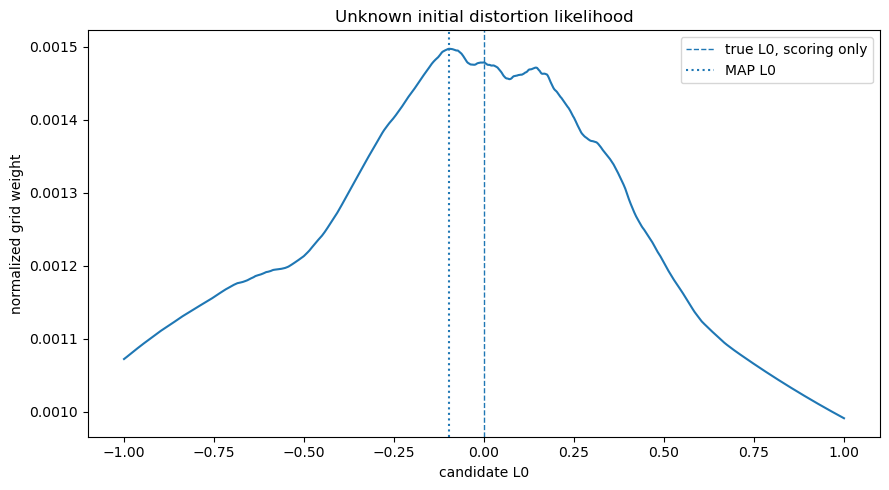

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part4_unknown_l0_likelihood.png


In [4]:
likelihood_table = pd.DataFrame({
    "candidate_l0": (
        candidate_l0
    ),
    "log_likelihood_shifted": (
        shifted
    ),
    "normalized_weight": (
        weights
    ),
})

likelihood_table.to_csv(
    DATA_DIR
    / "part4_unknown_l0_grid_likelihood.csv",
    index=False,
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    candidate_l0,
    weights,
)

plt.axvline(
    TRUE_L0,
    linestyle="--",
    linewidth=1.0,
    label="true L0, scoring only",
)

plt.axvline(
    map_l0,
    linestyle=":",
    linewidth=1.5,
    label="MAP L0",
)

plt.xlabel(
    "candidate L0"
)
plt.ylabel(
    "normalized grid weight"
)
plt.title(
    "Unknown initial distortion likelihood"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "part4_unknown_l0_likelihood.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

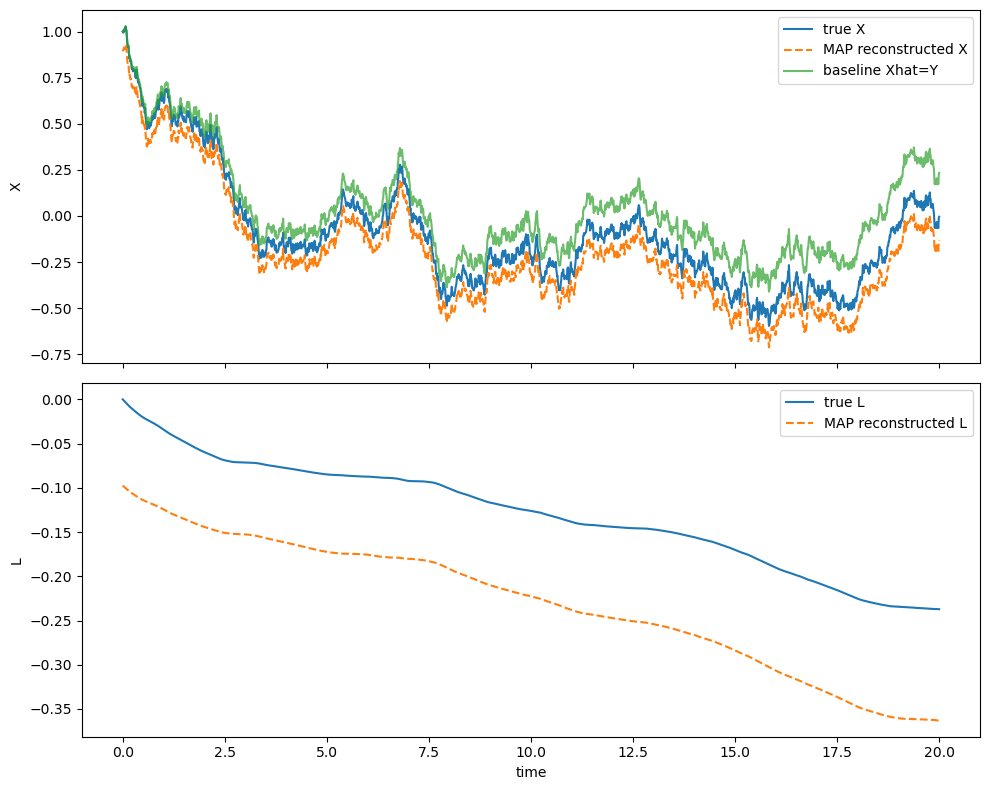

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part4_hidden_state_reconstruction.png


In [5]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 8),
    sharex=True,
)

axes[0].plot(
    time,
    x,
    label="true X",
)

axes[0].plot(
    time,
    x_map,
    linestyle="--",
    label="MAP reconstructed X",
)

axes[0].plot(
    time,
    x_baseline,
    alpha=0.7,
    label="baseline Xhat=Y",
)

axes[0].set_ylabel("X")
axes[0].legend()

axes[1].plot(
    time,
    l,
    label="true L",
)

axes[1].plot(
    time,
    l_map,
    linestyle="--",
    label="MAP reconstructed L",
)

axes[1].set_ylabel("L")
axes[1].set_xlabel("time")
axes[1].legend()

plt.tight_layout()

path = (
    RESULT_DIR
    / "part4_hidden_state_reconstruction.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

# Part IV Interpretation

With exact model parameters, exact observation history, and known $L_0$, the hidden history is determined by an ordinary initial-value problem.

Therefore observing only one coordinate does not by itself imply nonidentifiability.

When $L_0$ is unknown, the same problem becomes statistical.

The grid likelihood reports which candidate initial distortions are supported by the observed increments and how much uncertainty remains.

The true hidden paths are used only for scoring after inference, not as observations.